<a href="https://www.kaggle.com/code/burakaltunda/tedarik-zincir-sigorta-maliyet-analizi-ipynb?scriptVersionId=360562271" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Import Libs

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split,cross_val_score, KFold, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier,IsolationForest
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Lasso,Ridge, LinearRegression
from sklearn.tree import DecisionTreeRegressor,plot_tree
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

import warnings 
warnings.filterwarnings("ignore")

# Import Dataset

In [2]:
df = pd.read_csv("/kaggle/input/datasets/irakozekelly/supply-chain-shipment-pricing-dataset/Supply_Chain_Shipment_Pricing_Dataset.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10324 entries, 0 to 10323
Data columns (total 33 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   id                            10324 non-null  int64  
 1   project code                  10324 non-null  object 
 2   pq #                          10324 non-null  object 
 3   po / so #                     10324 non-null  object 
 4   asn/dn #                      10324 non-null  object 
 5   country                       10324 non-null  object 
 6   managed by                    10324 non-null  object 
 7   fulfill via                   10324 non-null  object 
 8   vendor inco term              10324 non-null  object 
 9   shipment mode                 9964 non-null   object 
 10  pq first sent to client date  10324 non-null  object 
 11  po sent to vendor date        10324 non-null  object 
 12  scheduled delivery date       10324 non-null  object 
 13  d

remove --> id,
target encoding --> project code


In [3]:
df.isnull().sum().sort_values(ascending=False)

dosage                          1736
shipment mode                    360
line item insurance (usd)        287
id                                 0
project code                       0
country                            0
managed by                         0
po / so #                          0
pq #                               0
vendor inco term                   0
pq first sent to client date       0
po sent to vendor date             0
scheduled delivery date            0
delivered to client date           0
delivery recorded date             0
fulfill via                        0
asn/dn #                           0
sub classification                 0
product group                      0
molecule/test type                 0
vendor                             0
brand                              0
dosage form                        0
unit of measure (per pack)         0
item description                   0
line item quantity                 0
line item value                    0
u

In [4]:
df.head(20)

,id,project code,pq #,po / so #,asn/dn #,country,managed by,fulfill via,vendor inco term,shipment mode,...,unit of measure (per pack),line item quantity,line item value,pack price,unit price,manufacturing site,first line designation,weight (kilograms),freight cost (usd),line item insurance (usd)
0,1,100-CI-T01,Pre-PQ Process,SCMS-4,ASN-8,Côte d'Ivoire,PMO - US,Direct Drop,EXW,Air,...,30,19,551.00,29.00,0.97,Ranbaxy Fine Chemicals LTD,True,13,780.34,NaN
1,3,108-VN-T01,Pre-PQ Process,SCMS-13,ASN-85,Vietnam,PMO - US,Direct Drop,EXW,Air,...,240,1000,6200.00,6.20,0.03,"Aurobindo Unit III, India",True,358,4521.5,NaN
2,4,100-CI-T01,Pre-PQ Process,SCMS-20,ASN-14,Côte d'Ivoire,PMO - US,Direct Drop,FCA,Air,...,100,500,40000.00,80.00,0.80,ABBVIE GmbH & Co.KG Wiesbaden,True,171,1653.78,NaN
3,15,108-VN-T01,Pre-PQ Process,SCMS-78,ASN-50,Vietnam,PMO - US,Direct Drop,EXW,Air,...,60,31920,127360.80,3.99,0.07,"Ranbaxy, Paonta Shahib, India",True,1855,16007.06,NaN
4,16,108-VN-T01,Pre-PQ Process,SCMS-81,ASN-55,Vietnam,PMO - US,Direct Drop,EXW,Air,...,60,38000,121600.00,3.20,0.05,"Aurobindo Unit III, India",True,7590,45450.08,NaN
5,23,112-NG-T01,Pre-PQ Process,SCMS-87,ASN-57,Nigeria,PMO - US,Direct Drop,EXW,Air,...,240,416,2225.60,5.35,0.02,"Aurobindo Unit III, India",True,504,5920.42,NaN
6,44,110-ZM-T01,Pre-PQ Process,SCMS-139,ASN-130,Zambia,PMO - US,Direct Drop,DDU,Air,...,90,135,4374.00,32.40,0.36,MSD South Granville Australia,True,328,Freight Included in Commodity Cost,NaN
7,45,109-TZ-T01,Pre-PQ Process,SCMS-140,ASN-94,Tanzania,PMO - US,Direct Drop,EXW,Air,...,60,16667,60834.55,3.65,0.06,"Aurobindo Unit III, India",True,1478,6212.41,NaN
8,46,112-NG-T01,Pre-PQ Process,SCMS-156,ASN-93,Nigeria,PMO - US,Direct Drop,EXW,Air,...,60,273,532.35,1.95,0.03,"Aurobindo Unit III, India",False,See ASN-93 (ID#:1281),See ASN-93 (ID#:1281),NaN
9,47,110-ZM-T01,Pre-PQ Process,SCMS-165,ASN-199,Zambia,PMO - US,Direct Drop,CIP,Air,...,120,2800,115080.00,41.10,0.34,ABBVIE (Abbott) St. P'burg USA,True,643,Freight Included in Commodity Cost,NaN


# EDA

In [5]:
print(f"Proje kodu:{df["project code"].nunique()}")
print(f"Talep no:{df["pq #"].nunique()}")
print(f"Satış no:{df["po / so #"].nunique()}")
print(f"Teslimat bildirim no:{df["asn/dn #"].nunique()}")

Proje kodu:142
Talep no:1237
Satış no:6233
Teslimat bildirim no:7030


Label Encoding --> Proje kodu 

Remove --> pq #, po / so #,asn/dn #

In [6]:
print(f"Ulkeler: {df["country"].nunique()}")
print("===============================================================================================================")
print(f"Yonetici Kurumlar:{df["managed by"].unique()} {df['managed by'].value_counts()}")
print("===============================================================================================================")
print(f"Gonderim Sekli: {df["fulfill via"].nunique()} {df["fulfill via"].unique()} {df['fulfill via'].value_counts()}")
print("===============================================================================================================")
print(f"Uluslararası Teslim Sekli: {df["vendor inco term"].nunique()} {df["vendor inco term"].value_counts()}")
print("===============================================================================================================")
print(f"Tasima Modu: {df["shipment mode"].nunique()} {df["shipment mode"].unique()} {df['shipment mode'].value_counts()}")
print("===============================================================================================================")
print(f"Urun Grubu: {df["product group"].nunique()} {df["product group"].unique()} {df['product group'].value_counts()}")
print("===============================================================================================================")
print(f"Alt Grup: {df["sub classification"].nunique()} {df["sub classification"].unique()} {df['sub classification'].value_counts()}")
print("===============================================================================================================")
print(f"Firma: {df["vendor"].nunique()}")
print("===============================================================================================================")
print(f"Urun Tanımı: {df["item description"].nunique()}")
print("===============================================================================================================")
print(f"Test Tipi: {df["molecule/test type"].nunique()}")
print("===============================================================================================================")
print(f"Marka: {df["brand"].nunique()}")
print("===============================================================================================================")
print(f"Dozajlar: {df["dosage"].nunique()} {df["dosage"].unique()}")
print("===============================================================================================================")
print(f"Dozaj Formu: {df["dosage form"].nunique()} {df["dosage form"].unique()}")
print("===============================================================================================================")
print(f"Paket Bası Tablet Sayısı: {df["unit of measure (per pack)"].nunique()} {df["unit of measure (per pack)"].unique()}")
print("===============================================================================================================")
print(f"Üretim Tesisi: {df["manufacturing site"].nunique()}")

Ulkeler: 43
Yonetici Kurumlar:['PMO - US' 'South Africa Field Office' 'Haiti Field Office'
 'Ethiopia Field Office'] managed by
PMO - US                     10265
South Africa Field Office       57
Haiti Field Office               1
Ethiopia Field Office            1
Name: count, dtype: int64
Gonderim Sekli: 2 ['Direct Drop' 'From RDC'] fulfill via
From RDC       5404
Direct Drop    4920
Name: count, dtype: int64
Uluslararası Teslim Sekli: 8 vendor inco term
N/A - From RDC    5404
EXW               2778
DDP               1443
FCA                397
CIP                275
DDU                 15
DAP                  9
CIF                  3
Name: count, dtype: int64
Tasima Modu: 4 ['Air' nan 'Truck' 'Air Charter' 'Ocean'] shipment mode
Air            6113
Truck          2830
Air Charter     650
Ocean           371
Name: count, dtype: int64
Urun Grubu: 5 ['HRDT' 'ARV' 'ACT' 'MRDT' 'ANTM'] product group
ARV     8550
HRDT    1728
ANTM      22
ACT       16
MRDT       8
Name: count, dtype: in

label encoding -->tüm kategorik verilere uygulanacak

In [7]:
df['freight cost (usd)'].value_counts()
print(f"Kategoriklerin Toplam Sayısı:{df[pd.to_numeric(df['freight cost (usd)'], errors='coerce').isna()]['freight cost (usd)'].value_counts().sum()}")
print("==============================================================================================================================")
print(f"Kategoriklerin Tek Tek Sayısı:{df[pd.to_numeric(df['freight cost (usd)'], errors='coerce').isna()]['freight cost (usd)'].value_counts()}")

Kategoriklerin Toplam Sayısı:4126
Kategoriklerin Tek Tek Sayısı:freight cost (usd)
Freight Included in Commodity Cost    1442
Invoiced Separately                    239
See DN-304 (ID#:10589)                  16
See ASN-32231 (ID#:13648)               14
See ASN-31750 (ID#:19272)               14
                                      ... 
See DN-4011 (ID#:84426)                  1
See DN-3903 (ID#:86131)                  1
See DN-3867 (ID#:84968)                  1
See DN-4016 (ID#:84996)                  1
See DN-3866 (ID#:85519)                  1
Name: count, Length: 1301, dtype: int64


paket ucretine dahil yada değil gibi sınıflandırılabilir

In [8]:
print(f"Kategoriklerin Toplam Sayısı:{df[pd.to_numeric(df['weight (kilograms)'], errors='coerce').isna()]['weight (kilograms)'].value_counts().sum()}")
print("==============================================================================================================================")
print(f"Kategoriklerin Tek Tek Sayısı:{df[pd.to_numeric(df['weight (kilograms)'], errors='coerce').isna()]['weight (kilograms)'].value_counts()}")

Kategoriklerin Toplam Sayısı:3952
Kategoriklerin Tek Tek Sayısı:weight (kilograms)
Weight Captured Separately    1507
See DN-304 (ID#:10589)          16
See ASN-32231 (ID#:13648)       14
See ASN-31750 (ID#:19272)       14
See ASN-28279 (ID#:13547)       13
                              ... 
See DN-4052 (ID#:85005)          1
See DN-4011 (ID#:84426)          1
See DN-3903 (ID#:86131)          1
See DN-3867 (ID#:84968)          1
See DN-4016 (ID#:84996)          1
Name: count, Length: 1300, dtype: int64


In [9]:
print(df["po sent to vendor date"].isna().sum())
print(df["scheduled delivery date"].isna().sum())
print(df["delivered to client date"].isna().sum())
print(df["delivery recorded date"].isna().sum())
print(df["pq first sent to client date"].isna().sum())

0
0
0
0
0


In [10]:
print(df["pq first sent to client date"].value_counts())

pq first sent to client date
Pre-PQ Process       2476
9/11/2014             205
Date Not Captured     205
7/11/2013             173
4/30/2014             123
                     ... 
1/23/2013               1
12/19/2014              1
8/2/2011                1
2/2/2012                1
8/29/2013               1
Name: count, Length: 765, dtype: int64


# GEDA

In [11]:
df.describe()

,id,unit of measure (per pack),line item quantity,line item value,pack price,unit price,line item insurance (usd)
count,10324.000000,10324.000000,10324.000000,1.032400e+04,10324.000000,10324.000000,10037.000000
mean,51098.968229,77.990895,18332.534870,1.576506e+05,21.910241,0.611701,240.117626
std,31944.332496,76.579764,40035.302961,3.452921e+05,45.609223,3.275808,500.190568
min,1.000000,1.000000,1.000000,0.000000e+00,0.000000,0.000000,0.000000
25%,12795.750000,30.000000,408.000000,4.314593e+03,4.120000,0.080000,6.510000
50%,57540.500000,60.000000,3000.000000,3.047147e+04,9.300000,0.160000,47.040000
75%,83648.250000,90.000000,17039.750000,1.664471e+05,23.592500,0.470000,252.400000
max,86823.000000,1000.000000,619999.000000,5.951990e+06,1345.640000,238.650000,7708.440000


<Axes: >

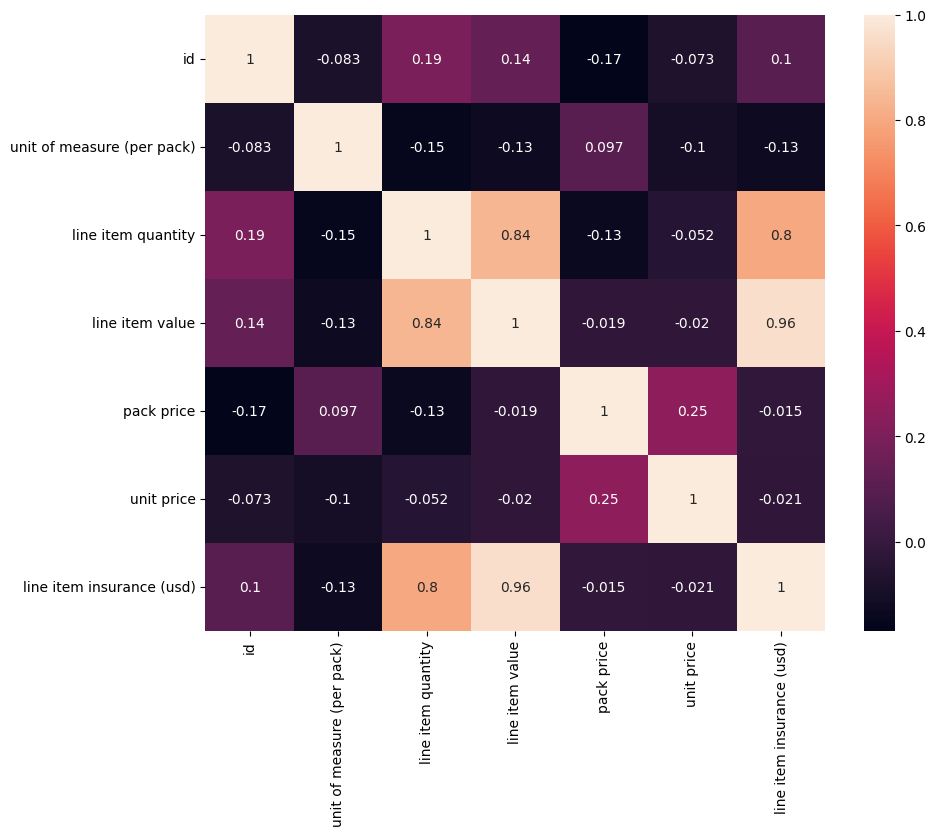

In [12]:
numeric_cols = df.select_dtypes(include=["number"])
matrix = numeric_cols.corr()

plt.figure(figsize=(10,8))
sns.heatmap(matrix,annot = True)

- Line item value ve line item quantity hedef niteliğin neredeyse aynısını yansıtır bu yüzden eleme yapacağız

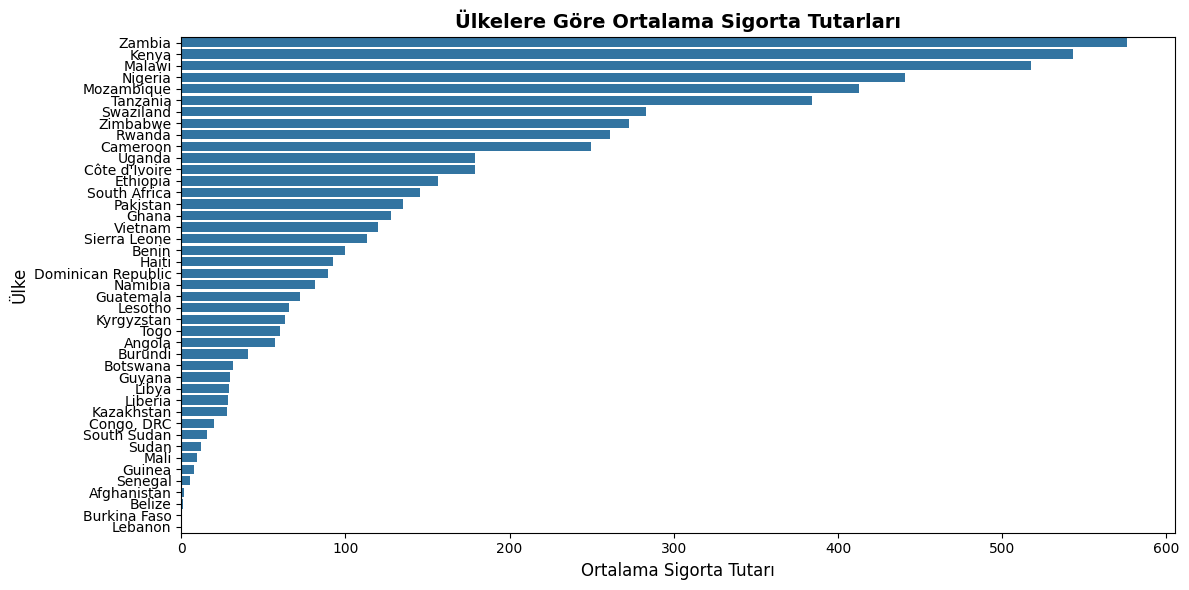

In [13]:
country_insurance = (
    df.groupby('country')['line item insurance (usd)']
    .mean()
    .reset_index()
    .sort_values(by='line item insurance (usd)', ascending=False)
)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=country_insurance,
    x='line item insurance (usd)',
    y='country'
)

plt.title('Ülkelere Göre Ortalama Sigorta Tutarları', fontsize=14, fontweight='bold')
plt.xlabel('Ortalama Sigorta Tutarı', fontsize=12)
plt.ylabel('Ülke', fontsize=12)
plt.tight_layout()
plt.show()

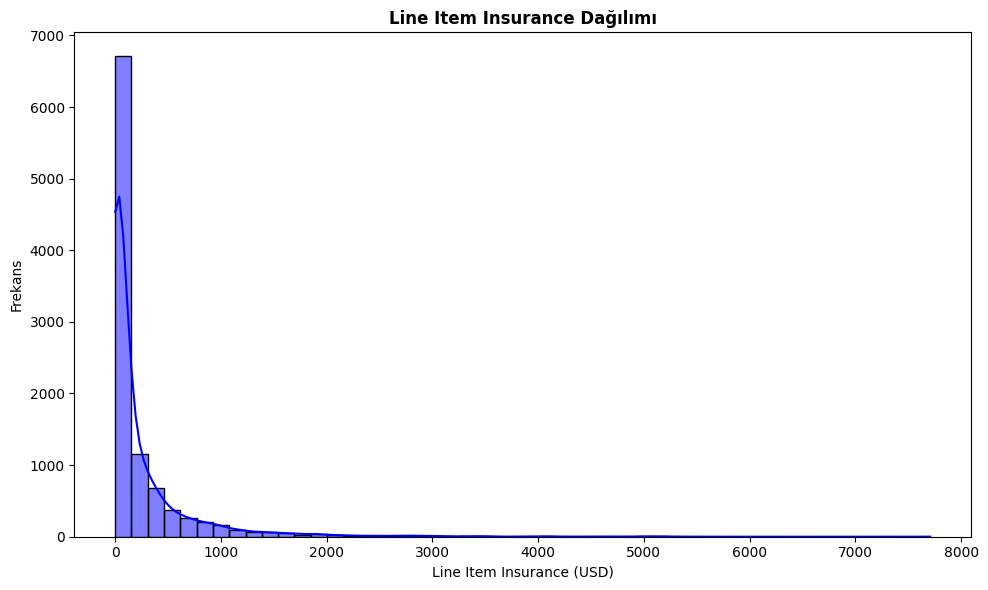

In [14]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df['line item insurance (usd)'].dropna(), kde=True, color='blue', bins=50
)
plt.title('Line Item Insurance Dağılımı', fontsize=12, fontweight='bold')
plt.xlabel('Line Item Insurance (USD)', fontsize=10)
plt.ylabel('Frekans', fontsize=10)

plt.tight_layout()
plt.show()

# Feature Engineering

In [15]:
def categorize_freight(val):
  val_str = str(val).strip()
  if "Freight Included" in val_str:
    return "Included_in_Cost"
  elif "Invoiced Separately" in val_str:
    return "Invoiced_Separately"
  elif "See DN-" in val_str or "See ASN-" in val_str:
    return "Referenced_Document"
  else:
    try:
      float(val_str)
      return "Numeric_Cost"
    except:
      return "Unknown"

df["freight_payment_type"] = df["freight cost (usd)"].apply(categorize_freight)
print(df["freight_payment_type"].value_counts())

freight_payment_type
Numeric_Cost           6198
Referenced_Document    2445
Included_in_Cost       1442
Invoiced_Separately     239
Name: count, dtype: int64


# Feature Selection

In [16]:
remove_cols = ["id","pq #","po / so #","asn/dn #","weight (kilograms)","freight cost (usd)",
               "po sent to vendor date","scheduled delivery date","delivered to client date",
               "delivery recorded date","pq first sent to client date","line item value"]
df.drop(remove_cols, inplace=True, axis = 1)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10324 entries, 0 to 10323
Data columns (total 22 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   project code                10324 non-null  object 
 1   country                     10324 non-null  object 
 2   managed by                  10324 non-null  object 
 3   fulfill via                 10324 non-null  object 
 4   vendor inco term            10324 non-null  object 
 5   shipment mode               9964 non-null   object 
 6   product group               10324 non-null  object 
 7   sub classification          10324 non-null  object 
 8   vendor                      10324 non-null  object 
 9   item description            10324 non-null  object 
 10  molecule/test type          10324 non-null  object 
 11  brand                       10324 non-null  object 
 12  dosage                      8588 non-null   object 
 13  dosage form                 103

# Train Test Split

In [17]:
df_clean = df.dropna(subset=["line item insurance (usd)"]).copy()

X = df_clean.drop(columns=["line item insurance (usd)"])
y = df_clean["line item insurance (usd)"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Missing Value

In [18]:
X_train.isna().sum()

project code                     0
country                          0
managed by                       0
fulfill via                      0
vendor inco term                 0
shipment mode                  208
product group                    0
sub classification               0
vendor                           0
item description                 0
molecule/test type               0
brand                            0
dosage                        1326
dosage form                      0
unit of measure (per pack)       0
line item quantity               0
pack price                       0
unit price                       0
manufacturing site               0
first line designation           0
freight_payment_type             0
dtype: int64

remove --> line item insurance (usd)
knn imputer --> shipment mode,dosage

## Random Forest Imputer

In [19]:
numeric_cols = X_train.select_dtypes(include=["int64", "float64"]).columns
categorical_cols = X_train.select_dtypes(include=["object", "category"]).columns

X_train_cat_imputed = X_train.copy()
X_test_cat_imputed = X_test.copy()

for col in categorical_cols:
    train_not_null = X_train_cat_imputed[X_train_cat_imputed[col].notnull()]
    train_is_null = X_train_cat_imputed[X_train_cat_imputed[col].isnull()]
    test_is_null = X_test_cat_imputed[X_test_cat_imputed[col].isnull()]
    
    if len(train_is_null) > 0 or len(test_is_null) > 0:
        features = list(numeric_cols)
        
        X_sub_train = train_not_null[features]
        y_sub_train = train_not_null[col]
        
        rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
        rf_classifier.fit(X_sub_train, y_sub_train)
        
        if len(train_is_null) > 0:
            X_sub_null = train_is_null[features]
            predicted_values = rf_classifier.predict(X_sub_null)
            X_train_cat_imputed.loc[X_train_cat_imputed[col].isnull(), col] = predicted_values
            
        if len(test_is_null) > 0:
            X_sub_test_null = test_is_null[features]
            predicted_test_values = rf_classifier.predict(X_sub_test_null)
            X_test_cat_imputed.loc[X_test_cat_imputed[col].isnull(), col] = predicted_test_values

print(X_train_cat_imputed.isna().sum())
print("==============================")
print(X_test_cat_imputed.isna().sum())

project code                  0
country                       0
managed by                    0
fulfill via                   0
vendor inco term              0
shipment mode                 0
product group                 0
sub classification            0
vendor                        0
item description              0
molecule/test type            0
brand                         0
dosage                        0
dosage form                   0
unit of measure (per pack)    0
line item quantity            0
pack price                    0
unit price                    0
manufacturing site            0
first line designation        0
freight_payment_type          0
dtype: int64
project code                  0
country                       0
managed by                    0
fulfill via                   0
vendor inco term              0
shipment mode                 0
product group                 0
sub classification            0
vendor                        0
item description           

# Outlier

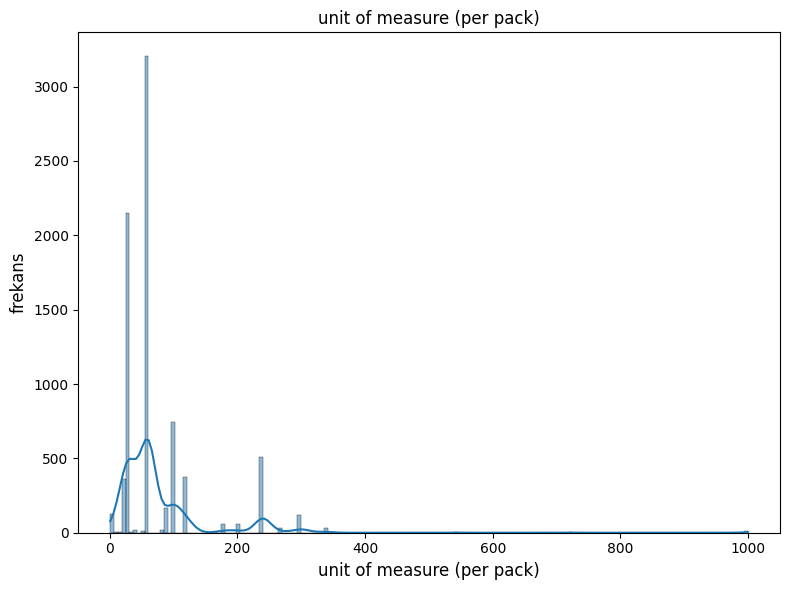

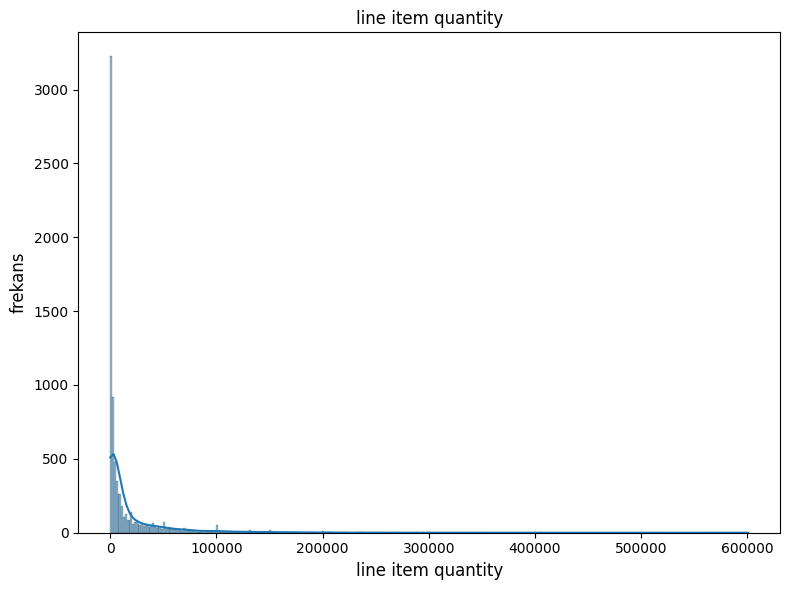

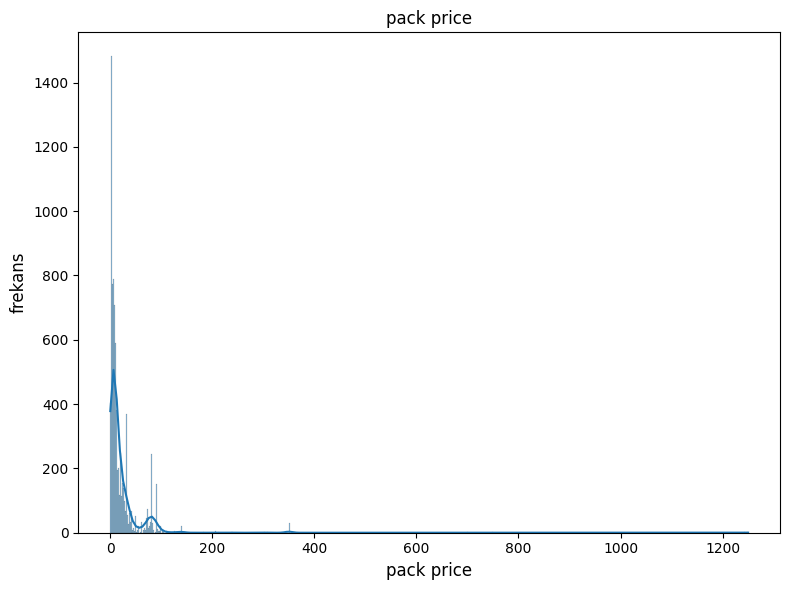

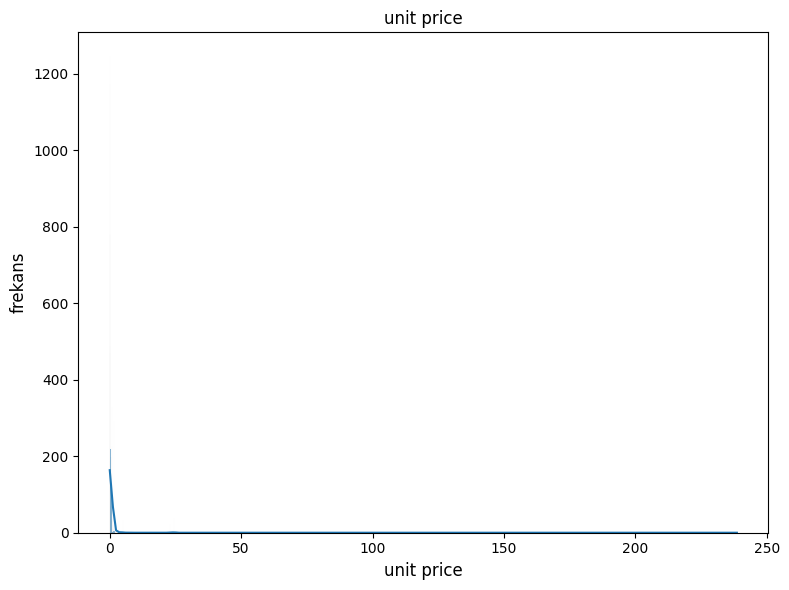

In [20]:
def show_features(df,feature):
    plt.figure(figsize=(8,6))
    sns.histplot(df[feature], kde=True)
    plt.title(feature)
    plt.xlabel(feature,fontsize=12)
    plt.ylabel("frekans",fontsize=12)
    plt.tight_layout()
    plt.show()
numeric_cols = X_train_cat_imputed.select_dtypes(include=['int64', 'float64']).columns

for i in numeric_cols:
    show_features(X_train_cat_imputed, i)
    

## Izolation Forest

In [21]:
iso = IsolationForest(contamination=0.01, random_state=42, n_jobs=-1)

train_pred = iso.fit_predict(X_train_cat_imputed[numeric_cols])

mask = train_pred != -1

X_train_clean = X_train_cat_imputed.loc[mask]
y_train_clean = y_train.loc[mask]

print(f"Orijinal X_train: {len(X_train_cat_imputed)}")
print(f"Isolation Forest:{len(X_train_clean)}")

Orijinal X_train: 8029
Isolation Forest:7948


# Feature Encoding

In [22]:
oe = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)

X_train_clean[categorical_cols] = oe.fit_transform(X_train_clean[categorical_cols])
X_test_clean = X_test_cat_imputed.copy()
X_test_clean[categorical_cols] = oe.transform(X_test_cat_imputed[categorical_cols])

In [23]:
X_train_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7948 entries, 5857 to 7557
Data columns (total 21 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   project code                7948 non-null   float64
 1   country                     7948 non-null   float64
 2   managed by                  7948 non-null   float64
 3   fulfill via                 7948 non-null   float64
 4   vendor inco term            7948 non-null   float64
 5   shipment mode               7948 non-null   float64
 6   product group               7948 non-null   float64
 7   sub classification          7948 non-null   float64
 8   vendor                      7948 non-null   float64
 9   item description            7948 non-null   float64
 10  molecule/test type          7948 non-null   float64
 11  brand                       7948 non-null   float64
 12  dosage                      7948 non-null   float64
 13  dosage form                 7948 no

In [24]:
X_train_clean["first line designation"] = X_train_clean["first line designation"].astype(int)
X_test_clean["first line designation"] = X_test_clean["first line designation"].astype(int)
X_train_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7948 entries, 5857 to 7557
Data columns (total 21 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   project code                7948 non-null   float64
 1   country                     7948 non-null   float64
 2   managed by                  7948 non-null   float64
 3   fulfill via                 7948 non-null   float64
 4   vendor inco term            7948 non-null   float64
 5   shipment mode               7948 non-null   float64
 6   product group               7948 non-null   float64
 7   sub classification          7948 non-null   float64
 8   vendor                      7948 non-null   float64
 9   item description            7948 non-null   float64
 10  molecule/test type          7948 non-null   float64
 11  brand                       7948 non-null   float64
 12  dosage                      7948 non-null   float64
 13  dosage form                 7948 no

# Scaling

In [25]:
scaler = StandardScaler()

X_train_clean[numeric_cols] = scaler.fit_transform(X_train_clean[numeric_cols])

X_test_clean[numeric_cols] = scaler.transform(X_test_clean[numeric_cols])

X_test_clean[numeric_cols].head()

,unit of measure (per pack),line item quantity,pack price,unit price
10016,-0.617956,-0.215861,-0.399371,-0.099460
6905,-0.230646,-0.069271,-0.478768,-0.215910
4728,-0.617956,0.347110,-0.698017,-0.261196
7787,0.543974,0.028701,0.085476,-0.177093
9529,-0.230646,-0.455770,-0.666984,-0.267665


# Modelling

In [26]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

pipelines = {
    "Linear Reg" : Pipeline([("model",LinearRegression())]),
    "Lasso" : Pipeline([("model",Lasso())]),
    "Ridge" : Pipeline([("model",Ridge())]),
    "Decision Tree" : Pipeline([("model", DecisionTreeRegressor())]),
    "AdaBoost": Pipeline([("model", AdaBoostRegressor(random_state=42))]),
    "Random Forest": Pipeline([("model", RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))]),
    "XGBoost": Pipeline([("model", XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, n_jobs=-1))])

}

print("R2 Skorları")
for name, pipe in pipelines.items():
    scores = cross_val_score(pipe, X_train_clean, y_train_clean, cv=kf, scoring="r2", n_jobs=-1)
    print(f"{name} -> R2 Skorları: {scores}")
    print(f"{name} -> Ortalama R2: {scores.mean()} (+/- {scores.std()})")

R2 Skorları
Linear Reg -> R2 Skorları: [0.65766626 0.71988113 0.67929252 0.6310117  0.71914395]
Linear Reg -> Ortalama R2: 0.6813991110539099 (+/- 0.03467597206074802)
Lasso -> R2 Skorları: [0.65830008 0.71946324 0.67879447 0.63092904 0.71950519]
Lasso -> Ortalama R2: 0.68139840547255 (+/- 0.03460788693380284)
Ridge -> R2 Skorları: [0.65768317 0.71986155 0.67928822 0.63101138 0.71916808]
Ridge -> Ortalama R2: 0.6814024818083322 (+/- 0.03467471370478616)
Decision Tree -> R2 Skorları: [0.93354092 0.92546263 0.93765056 0.85848744 0.95119467]
Decision Tree -> Ortalama R2: 0.9212672455395511 (+/- 0.032476490064749355)
AdaBoost -> R2 Skorları: [0.45109307 0.67389621 0.5134582  0.58443884 0.48247575]
AdaBoost -> Ortalama R2: 0.541072416246865 (+/- 0.0797686708319497)
Random Forest -> R2 Skorları: [0.95915837 0.94665008 0.96036584 0.93097392 0.96333295]
Random Forest -> Ortalama R2: 0.9520962318710335 (+/- 0.012002807084675375)
XGBoost -> R2 Skorları: [0.95826199 0.94113305 0.95237579 0.932668

In [27]:
for name, model in pipelines.items():
    model.fit(X_train_clean, y_train_clean)
    
    y_pred = model.predict(X_test_clean)
    
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    
    print(f"--- {name} Performansı ---")
    print(f"R2 Skoru : {r2}")
    print(f"MAE      : {mae}")
    print(f"RMSE     : {rmse}")

--- Linear Reg Performansı ---
R2 Skoru : 0.6209769994894512
MAE      : 154.3455530976061
RMSE     : 322.87578592753897
--- Lasso Performansı ---
R2 Skoru : 0.6251182239096309
MAE      : 153.31689873159823
RMSE     : 321.1070628078292
--- Ridge Performansı ---
R2 Skoru : 0.6210067816641802
MAE      : 154.3412923851429
RMSE     : 322.8631005074421
--- Decision Tree Performansı ---
R2 Skoru : 0.9536251971097608
MAE      : 37.351807768924296
RMSE     : 112.9389464223542
--- AdaBoost Performansı ---
R2 Skoru : 0.45259352726489
MAE      : 356.77347116008133
RMSE     : 388.0231686232658
--- Random Forest Performansı ---
R2 Skoru : 0.9640484201027256
MAE      : 29.520831404032155
RMSE     : 99.44013008749542
--- XGBoost Performansı ---
R2 Skoru : 0.9558420278687758
MAE      : 30.671929054411343
RMSE     : 110.2065111976803


In [28]:
models_and_params = {
    "AdaBoost": (
        AdaBoostRegressor(random_state=42),
        {
            "n_estimators": [340, 350, 360],
            "learning_rate": [0.01]
        }
    ),
    "Random Forest": (
        RandomForestRegressor(random_state=42, n_jobs=-1),
        {
            "n_estimators": [250, 300, 320],
            "max_depth": [28, 30, 32],
            "min_samples_split": [6, 7, 8],
        }
    ),
    "XGBoost": (
        XGBRegressor(random_state=42, n_jobs=-1),
        {
            "n_estimators": [95, 100, 115],
            "learning_rate": [0.2, 0.3],
            "max_depth": [4, 5, 6, 7],
            "subsample": [0.7, 0.75, 0.8]
        }
    )
}

In [29]:
for name, (model, params) in models_and_params.items():
    print(f"====={name}=====")
    
    search = RandomizedSearchCV(
        estimator=model,
        param_distributions=params,
        n_iter=10,        
        cv=kf,           
        scoring='r2',
        verbose=1,        
        random_state=42,
        n_jobs=-1     
    )
    
    search.fit(X_train_clean, y_train_clean)
    
    print(f"{name} En İyi R2: {search.best_score_:}")
    print(f"{name} En İyi Parametreler : {search.best_params_}")
    

=====AdaBoost=====
Fitting 5 folds for each of 3 candidates, totalling 15 fits
AdaBoost En İyi R2: 0.7626171843779288
AdaBoost En İyi Parametreler : {'n_estimators': 360, 'learning_rate': 0.01}
=====Random Forest=====
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Random Forest En İyi R2: 0.9500084500522341
Random Forest En İyi Parametreler : {'n_estimators': 320, 'min_samples_split': 6, 'max_depth': 30}
=====XGBoost=====
Fitting 5 folds for each of 10 candidates, totalling 50 fits
XGBoost En İyi R2: 0.9543332821058623
XGBoost En İyi Parametreler : {'subsample': 0.75, 'n_estimators': 95, 'max_depth': 7, 'learning_rate': 0.2}


## XGB

In [30]:
xgb = XGBRegressor(
    n_estimators=95,
    max_depth=7,
    learning_rate=0.2,
    subsample=0.75,
    random_state=42,
    n_jobs=-1
)

xgb.fit(X_train_clean, y_train_clean)

y_pred_xgb = xgb.predict(X_test_clean)

final_r2 = r2_score(y_test, y_pred_xgb)
final_mae = mean_absolute_error(y_test, y_pred_xgb)
final_rmse = np.sqrt(mean_squared_error(y_test, y_pred_xgb))

print("=====XGBOOST SONUÇLARI=====")
print(f"Test R2 Skoru : {final_r2}")
print(f"Test MAE      : {final_mae}")
print(f"Test RMSE     : {final_rmse}")

=====XGBOOST SONUÇLARI=====
Test R2 Skoru : 0.9577213252269438
Test MAE      : 28.21081385187682
Test RMSE     : 107.83590230081202


## RF

In [31]:
rf = RandomForestRegressor(
    n_estimators=320,
    max_depth=30,
    min_samples_split=6,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train_clean, y_train_clean)

y_pred_rf = rf.predict(X_test_clean)

final_r2_rf = r2_score(y_test, y_pred_rf)
final_mae_rf = mean_absolute_error(y_test, y_pred_rf)
final_rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))

print("=====RANDOM FOREST SONUÇLARI=====")
print(f"Test R2 Skoru : {final_r2_rf}")
print(f"Test MAE      : {final_mae_rf}")
print(f"Test RMSE     : {final_rmse_rf}")

=====RANDOM FOREST SONUÇLARI=====
Test R2 Skoru : 0.961963588837299
Test MAE      : 30.212699036351438
Test RMSE     : 102.28276513286572


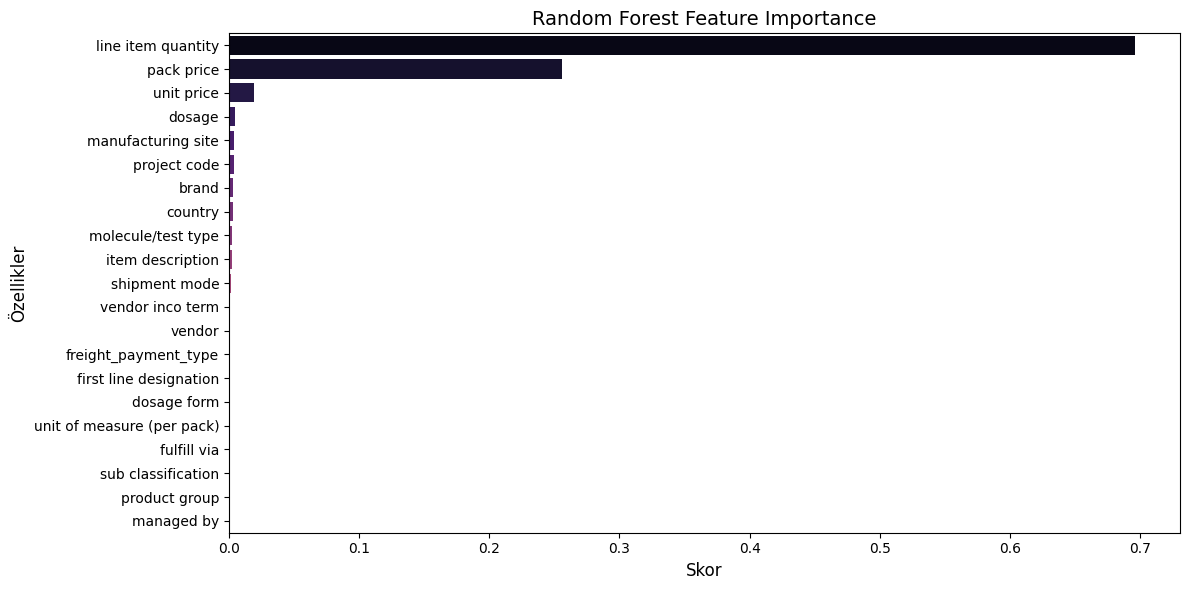

In [32]:
importances = rf.feature_importances_
feature_names = X_train_clean.columns

rf_importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
rf_importance_df = rf_importance_df.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(x='Importance', y='Feature', data=rf_importance_df, palette='magma')
plt.title('Random Forest Feature Importance', fontsize=14)
plt.xlabel('Skor', fontsize=12)
plt.ylabel('Özellikler', fontsize=12)
plt.tight_layout()
plt.show()

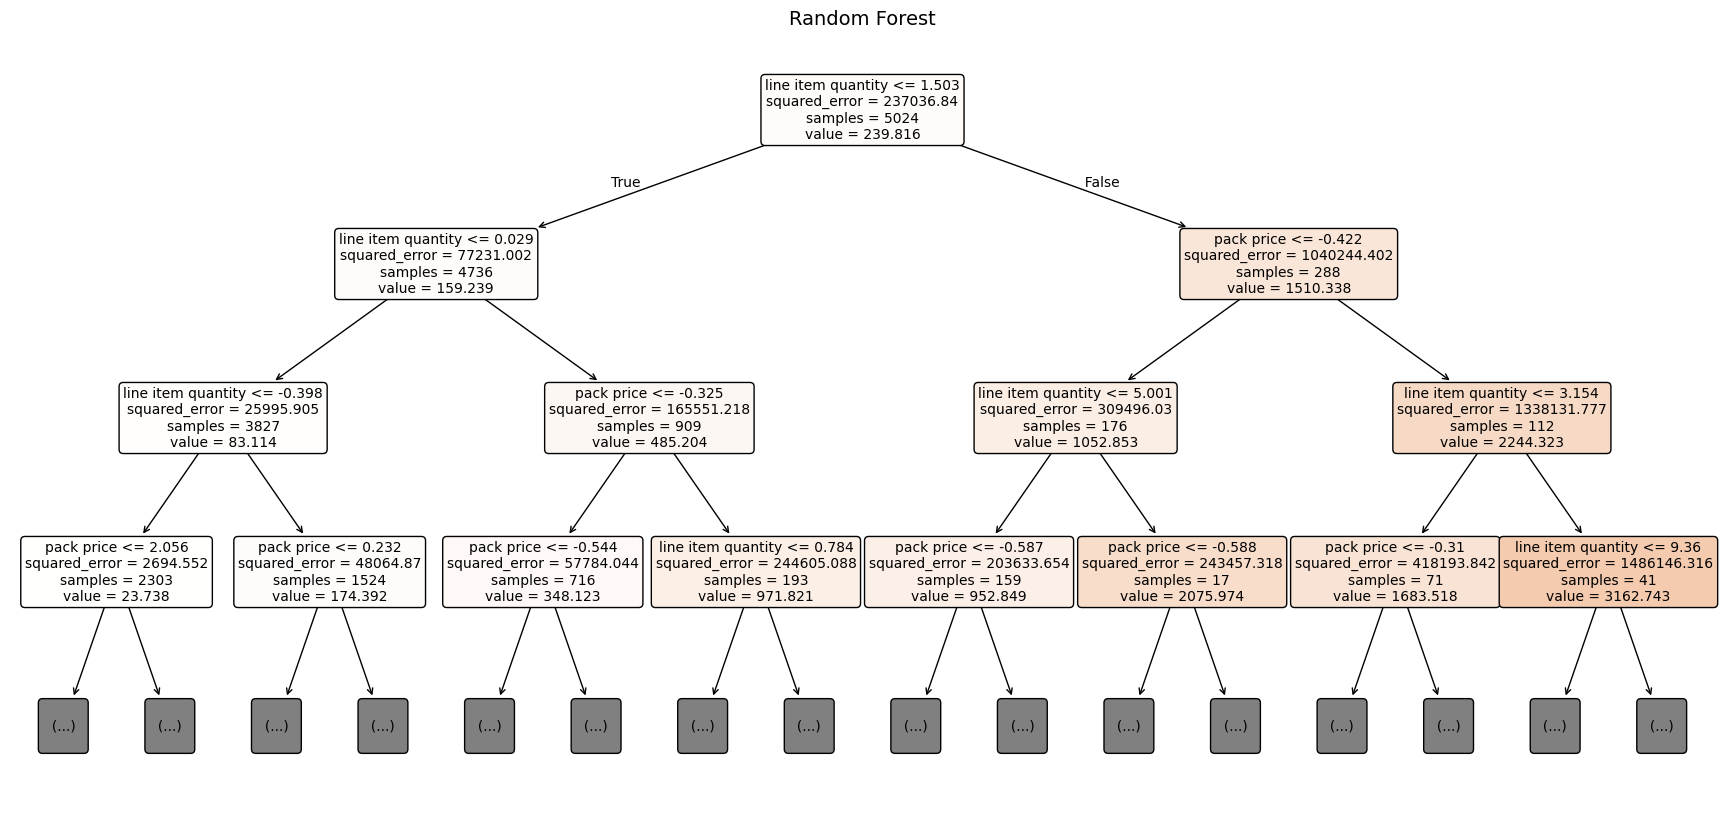

In [33]:
first_tree = rf.estimators_[0]

plt.figure(figsize=(22, 10))

plot_tree(first_tree, 
          feature_names=X_train_clean.columns, 
          filled=True, 
          rounded=True, 
          fontsize=10, 
          max_depth=3) 

plt.title("Random Forest", fontsize=14)
plt.show()

# Notes
- Label Encoding, Target Encoding, Frekans Encoding yaptıktan sonra lineer modellerin büyük sayılı etiket alanın fiyatınında daha büyük olması gerekir gibi bir mantık kurma riski vardır
- bunun için bu encode yöntemleri ile birlikte ağaç tabanlı modeller kullanılır. lineer modeller ve yapay sinir ağları tercih edilmez
- line item value çok yüksek korelasyon(0.96) nedeniyle kaldırılmıştır.(neredeyse hedef değişkenle aynı şeyi ifade ediyor)
- KNN Imputerla eksik verileri dolduramayız çünkü kategorik verileri dolduramaz ve Label encoderla çalışamaz random forest classifier kullanarak bu eksik değerleri dolduracağız
- Outlier Detect için IQR yöntemi aykırı gibi gözüken ama sektörde normal olan bu değerleri outlier olarak işaretler çünkü veriler sağa çarpık bu yüzden en güvenilir yöntem izolasyon ağaçlarını kullanmaktır
- Encoder olarak label encoder birden fazla feature kullandığında bozulacağı için ordinal encoder kullandım.
- Lineer modeller verinin yapısı ve önişleme adımlarından sonra düzgün sonuçlar üretemez.
- Adaboost hiperparametre ayarlarından sonra gözle görülür bir biçimde iyileşmiştir ama hala çok yetersiz kalmaktadır. zayıf öğrenciler gürültüyü çözmekte etkisiz kalmıştır.
- Daha önce yaptığım *"line item value"* kolonunu kaldırmadığım Eğitim sonuçlarında xgb eğitim sırasında 0.97 gibi bir r2 skoru verirken test verisetinde 0.92 ye kadar düşmüştür.Yani bu durum overfitting'e sebep olmuştur.buna karşın random forest istikrarlı bir çizgide ilerlemiş ve sonuçları tutarlıdır overfiting'e yatkınlığı düşüktür. fakat sonradan fark etmem üzerine bu kolon kaldırılmıştır
